# AI651 PA2 - Question 1 diagram and Question 2 (Motion or Memory?)  [version 2a]

Clones the public repo (branch `PA2`) and runs everything top to bottom: **Runtime -> Change runtime type -> T4 GPU, then Run all** (about 1 hour; each model trains in about 5 minutes). Push your latest commit first, because the notebook clones the repo. Nothing uses Google Drive.

In [1]:
# 1. Setup
import os, torch
REPO = 'https://github.com/RazaTypesCode/DLSTG.git'
BRANCH = 'PA2'
if not os.path.exists('/content/DLSTG'):
    !git clone --branch $BRANCH --single-branch $REPO /content/DLSTG
else:
    !git -C /content/DLSTG pull
os.environ['PA2_RUNS'] = '/content/runs'
os.environ['PA2_DATA'] = '/content/data'
os.makedirs('/content/runs', exist_ok=True)
print('CUDA available:', torch.cuda.is_available(), '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU ONLY - switch runtime to T4 GPU')
!git -C /content/DLSTG log --oneline -3

Cloning into '/content/DLSTG'...
remote: Enumerating objects: 47, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 47 (delta 3), reused 46 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (47/47), 1020.14 KiB | 30.00 MiB/s, done.
Resolving deltas: 100% (3/3), done.
CUDA available: True | Tesla T4
6f36a5c (HEAD -> PA2, origin/PA2) Notebooks
5bf44fb First runs


/content/DLSTG/Question1
saved figures/q1_architecture.png


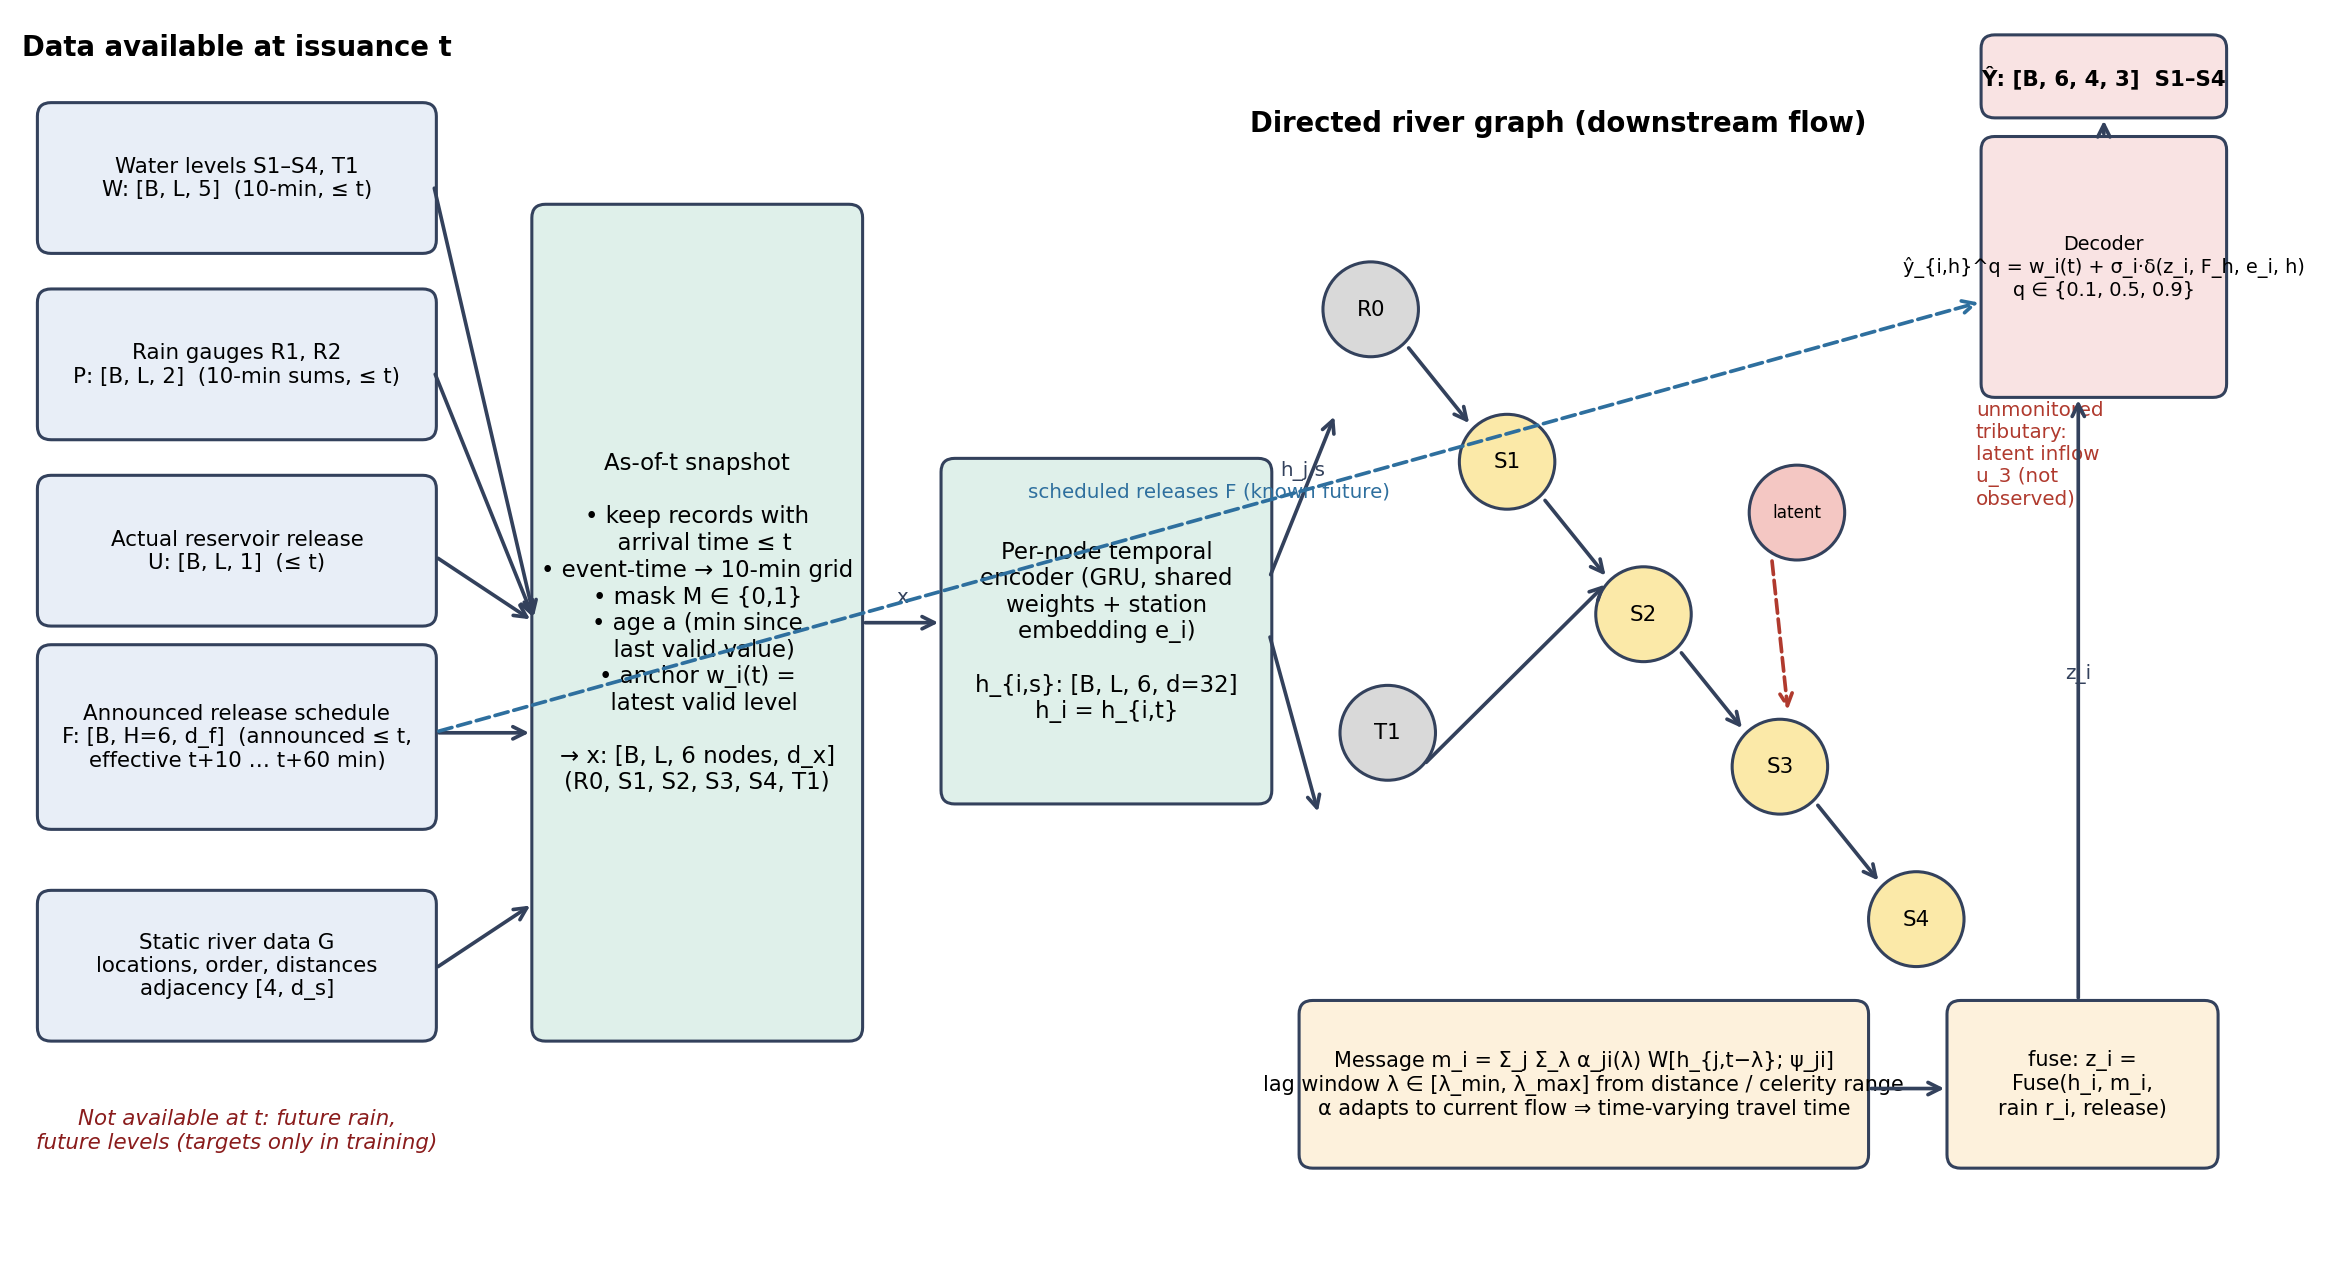

/content/DLSTG/Question2


In [2]:
# 2. Question 1: architecture diagram
%cd /content/DLSTG/Question1
!python q1_diagram.py
from IPython.display import Image, display
display(Image('figures/q1_architecture.png'))
%cd /content/DLSTG/Question2

/content/DLSTG/Question2
Traceback (most recent call last):
  File "/content/DLSTG/Question2/check_table1.py", line 14, in <module>
    for name, row in rows:
        ^^^^^^^^^
ValueError: too many values to unpack (expected 2)
100% 819M/819M [01:10<00:00, 11.6MB/s]
pixels kept: 103050, median speed: 3.318 px/frame
speed percentiles 10/25/50/75/90/99: [2.14 3.   3.32 3.89 4.12 4.67]
CAPTION: median speed = 3.32 px/frame; 103050 pixels kept from 950 frame pairs.


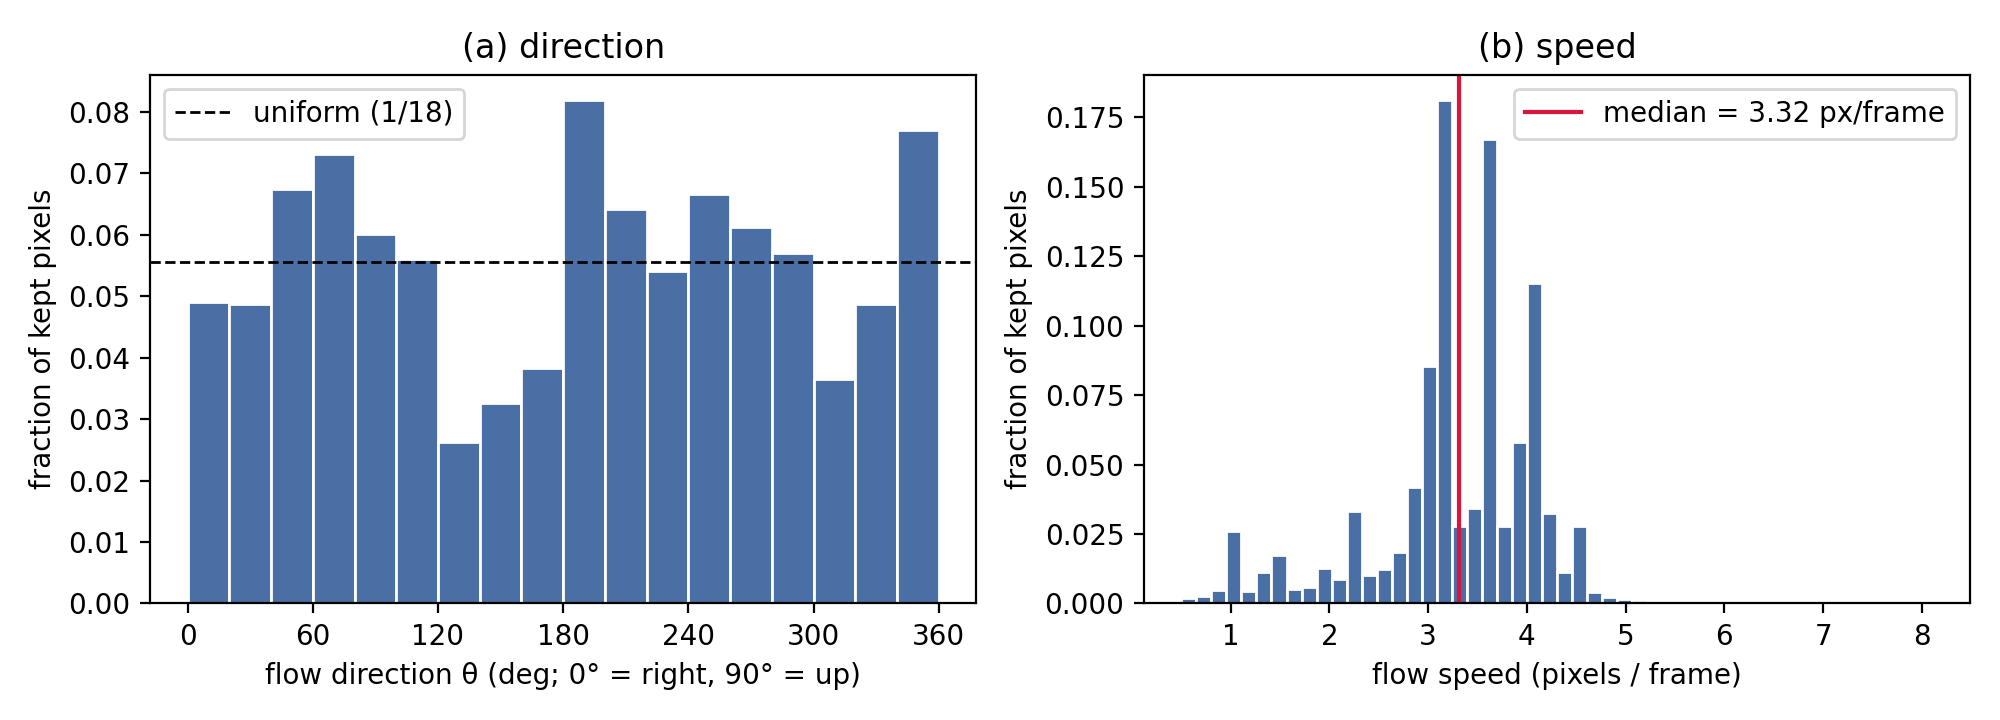

In [3]:
# 3. Question 2: Table 1 (transform and window checks) and Figure 1 (optical flow)
%cd /content/DLSTG/Question2
!python check_table1.py
!python fig1_flow.py
from IPython.display import Image, display
display(Image('figures/fig1.png'))

A seed 0: params=480784, reach=8px, device=cuda, speed_aug=False, sym_aug=False
{'epoch': 1, 'train_loss': 0.04611336587369442, 'sec': 12.436796426773071, 'val_E5': 0.03931237384676933}
{'epoch': 2, 'train_loss': 0.039667277783155444, 'sec': 9.954457759857178, 'val_E5': 0.03864384442567825}
{'epoch': 3, 'train_loss': 0.03866632142663002, 'sec': 10.088745832443237, 'val_E5': 0.03731665015220642}
{'epoch': 4, 'train_loss': 0.037125148028135296, 'sec': 10.256706714630127, 'val_E5': 0.035485707223415375}
{'epoch': 5, 'train_loss': 0.035262419506907464, 'sec': 10.459827184677124, 'val_E5': 0.033727776259183884}
{'epoch': 6, 'train_loss': 0.03358736798912287, 'sec': 10.676746368408203, 'val_E5': 0.03215678781270981}
{'epoch': 7, 'train_loss': 0.032248910620808605, 'sec': 11.018513441085815, 'val_E5': 0.03174572065472603}
{'epoch': 8, 'train_loss': 0.0313100755289197, 'sec': 11.237799644470215, 'val_E5': 0.0303132776170969}
{'epoch': 9, 'train_loss': 0.03040134447813034, 'sec': 11.09451818466

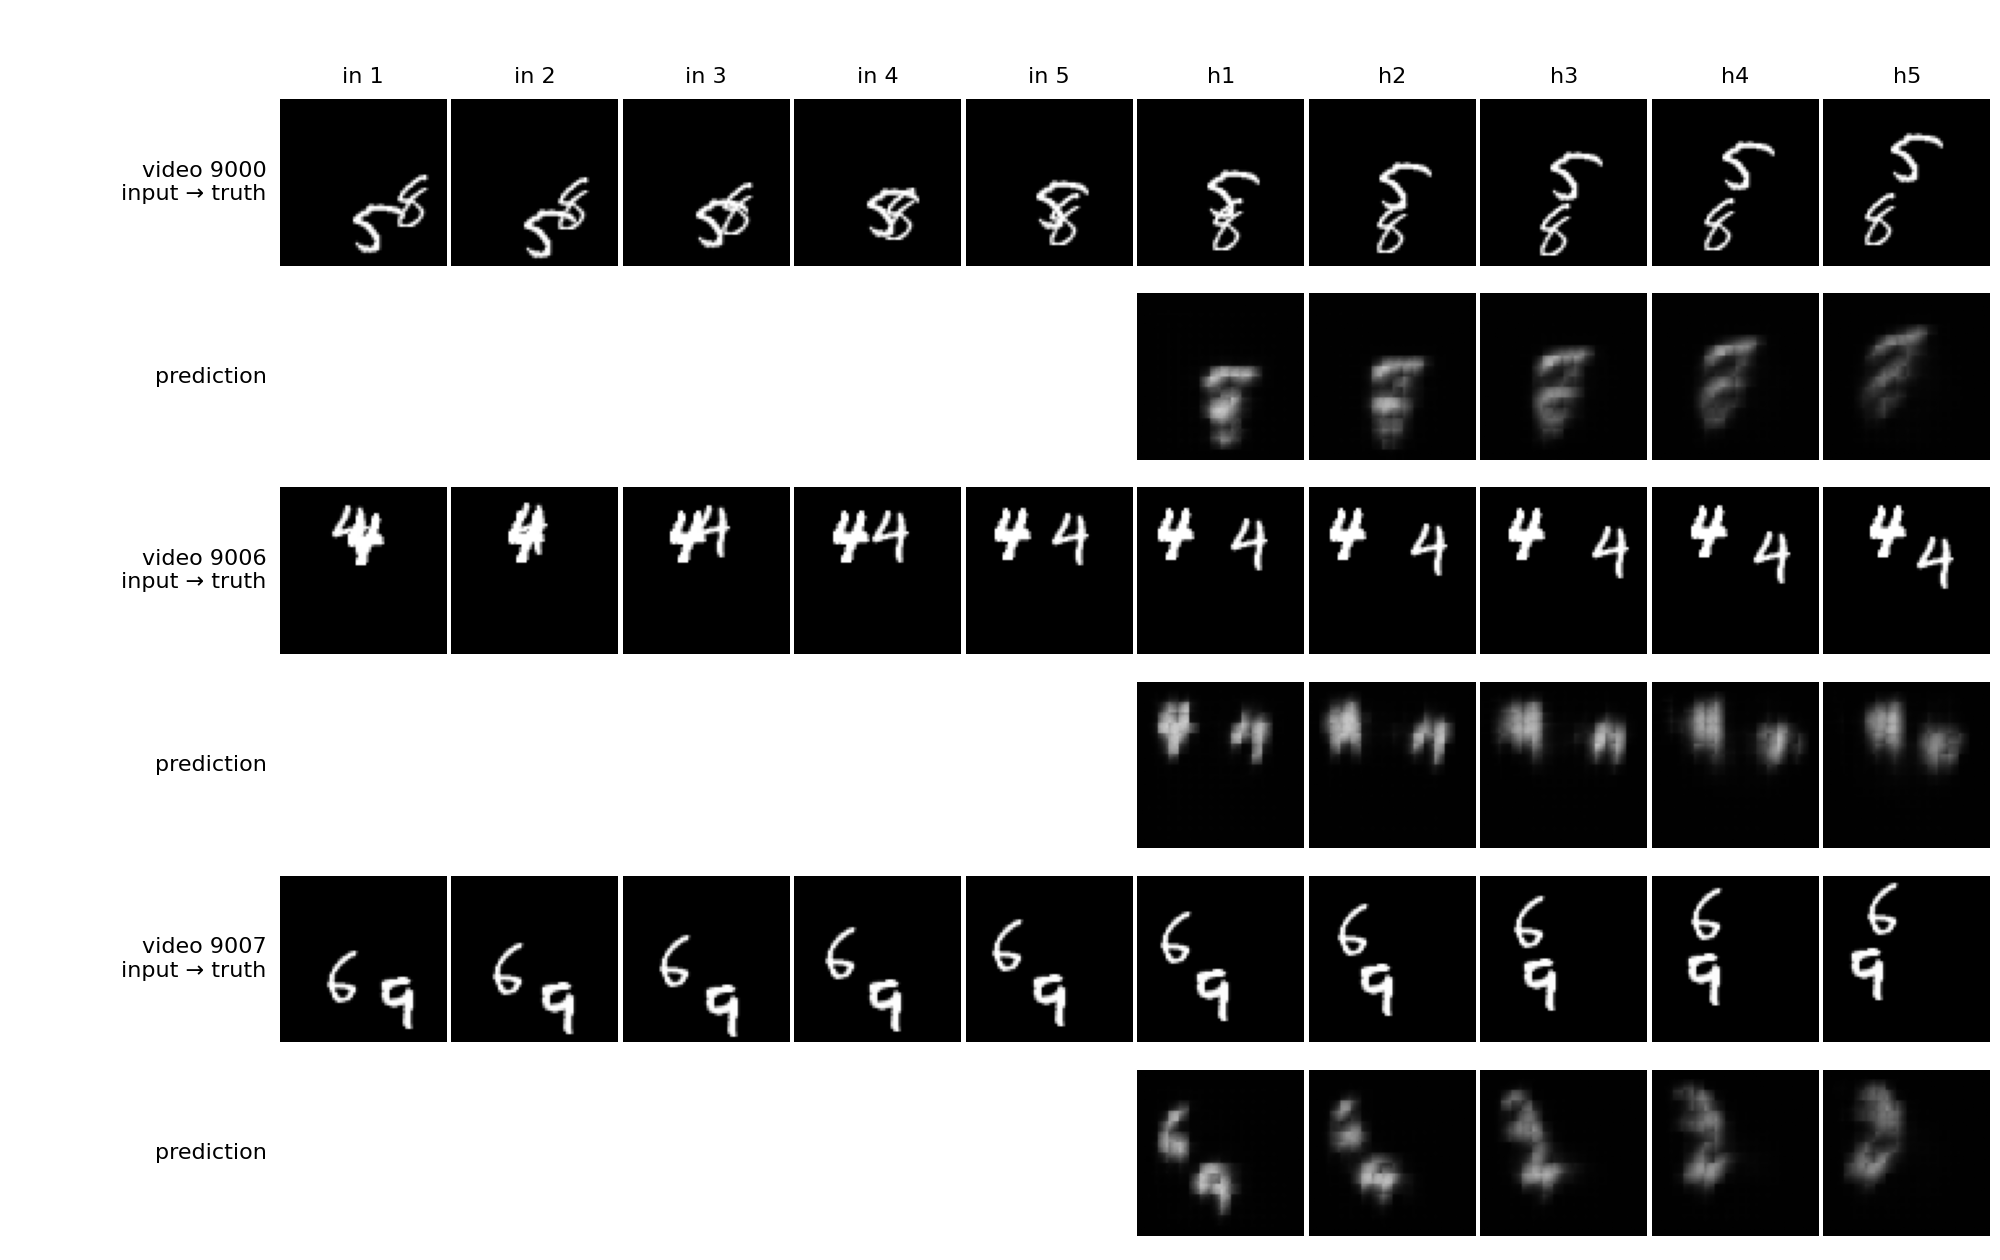

In [4]:
# 4. Model A (seeds 0, 1), then Table 2 and Figure 2
for s in (0, 1):
    !python train.py --model A --seed $s
!python stage_A1.py
!cat results/table2.md
display(Image('figures/fig2.png'))

| Model | E(5) | C_M | E_M | C_R | E_R |
|---|---|---|---|---|---|
| A (mean (s0, s1)) | 0.0222 (0.0225, 0.022) | 0.00163 (0.00155, 0.00171) | 0.0228 (0.0231, 0.0226) | 0.00288 (0.00254, 0.00321) | 0.024 (0.024, 0.0239) |
| Blank | 0.0426 | 0.00e+00 | 0.0426 | 0.00e+00 | 0.0426 |
| Copy-last | 0.0641 | 0.00e+00 | 0.0641 | 0.00e+00 | 0.0641 | 

 | Model | E(2) 1x | E(2) 2x | E(2) 3x | E(5) 1x | E(5) 2x |
|---|---|---|---|---|---|
| A (mean (s0, s1)) | 0.0189 (0.0191, 0.0186) | 0.0442 (0.0435, 0.0449) | 0.0511 (0.0509, 0.0514) | 0.0222 (0.0225, 0.022) | 0.0484 (0.0476, 0.0493) |
| Blank | 0.0426 | 0.0425 | 0.0426 | 0.0426 | 0.0425 |
| Copy-last | 0.0548 | 0.0661 | 0.0703 | 0.0641 | 0.0719 |
top-2 per-video C_M: [269, 499]  top-2 per-video C_R: [31, 150]
Figure 3 panels: [
 {
  "T": "M",
  "rank": 1,
  "test_index": 269,
  "png": "figures/fig3_M_rank1_video9269.png",
  "gif": "figures/gifs/fig3_M_rank1_video9269.gif"
 },
 {
  "T": "M",
  "rank": 2,
  "test_index": 499,
  "png": "figures/f

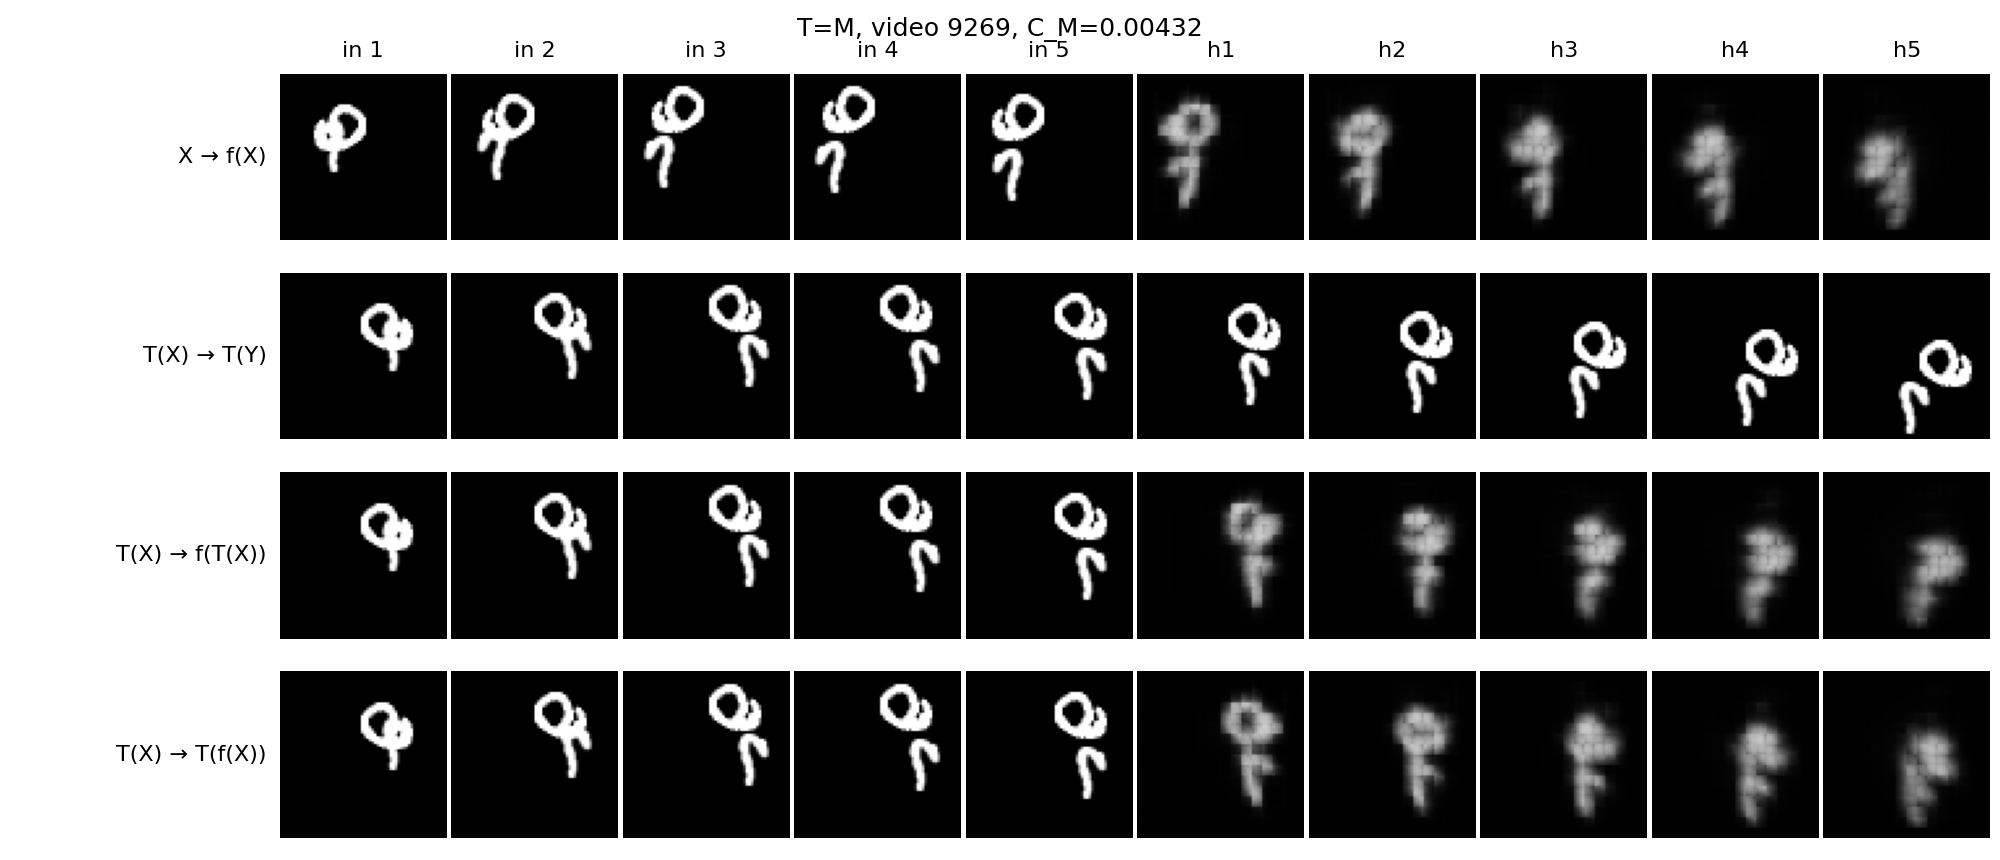

figures/fig3_M_rank2_video9499.png


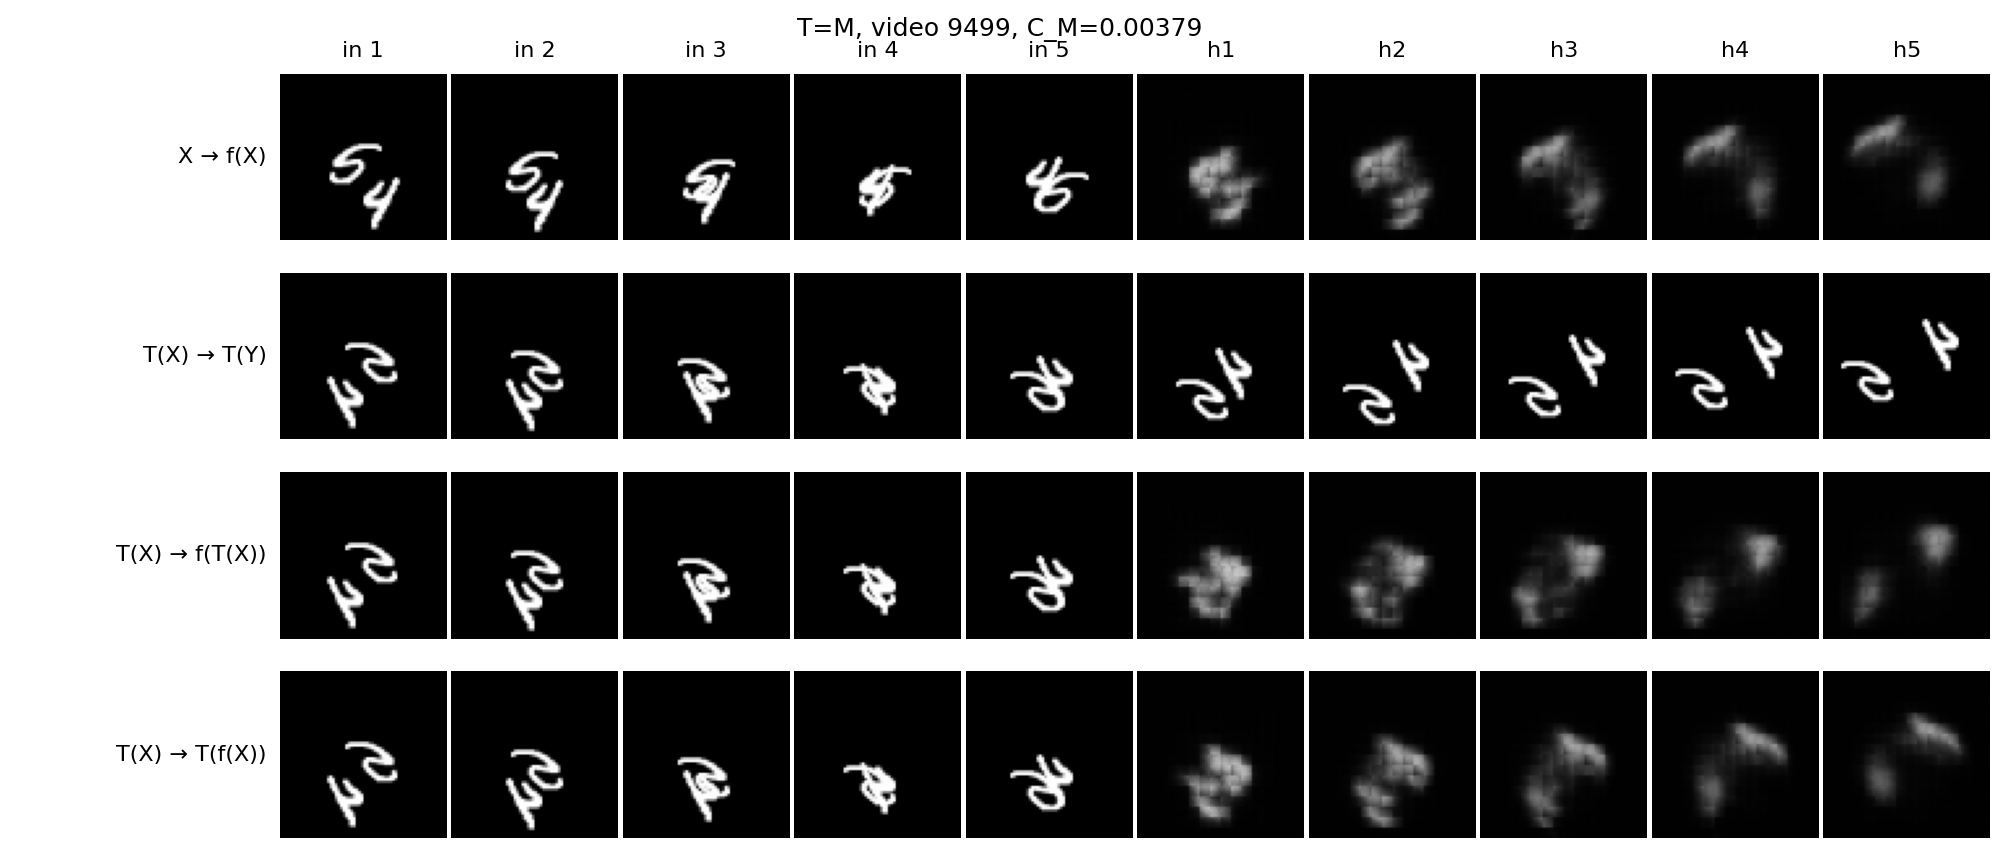

figures/fig3_R_rank1_video9031.png


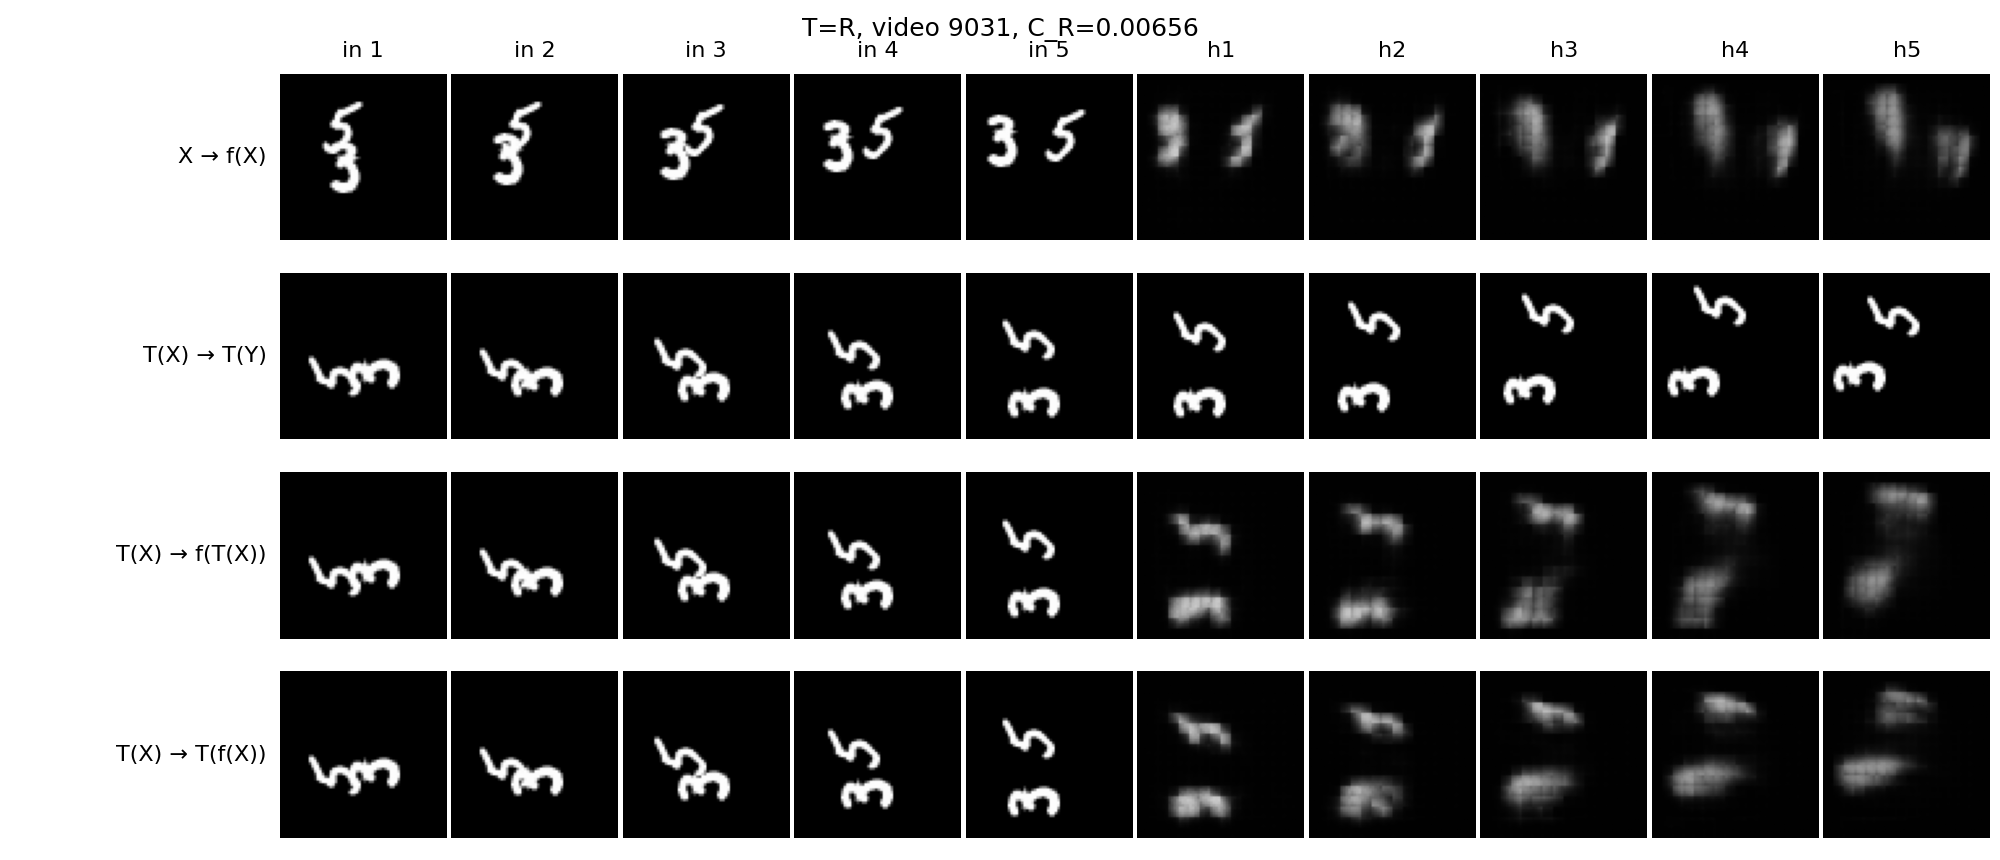

figures/fig3_R_rank2_video9150.png


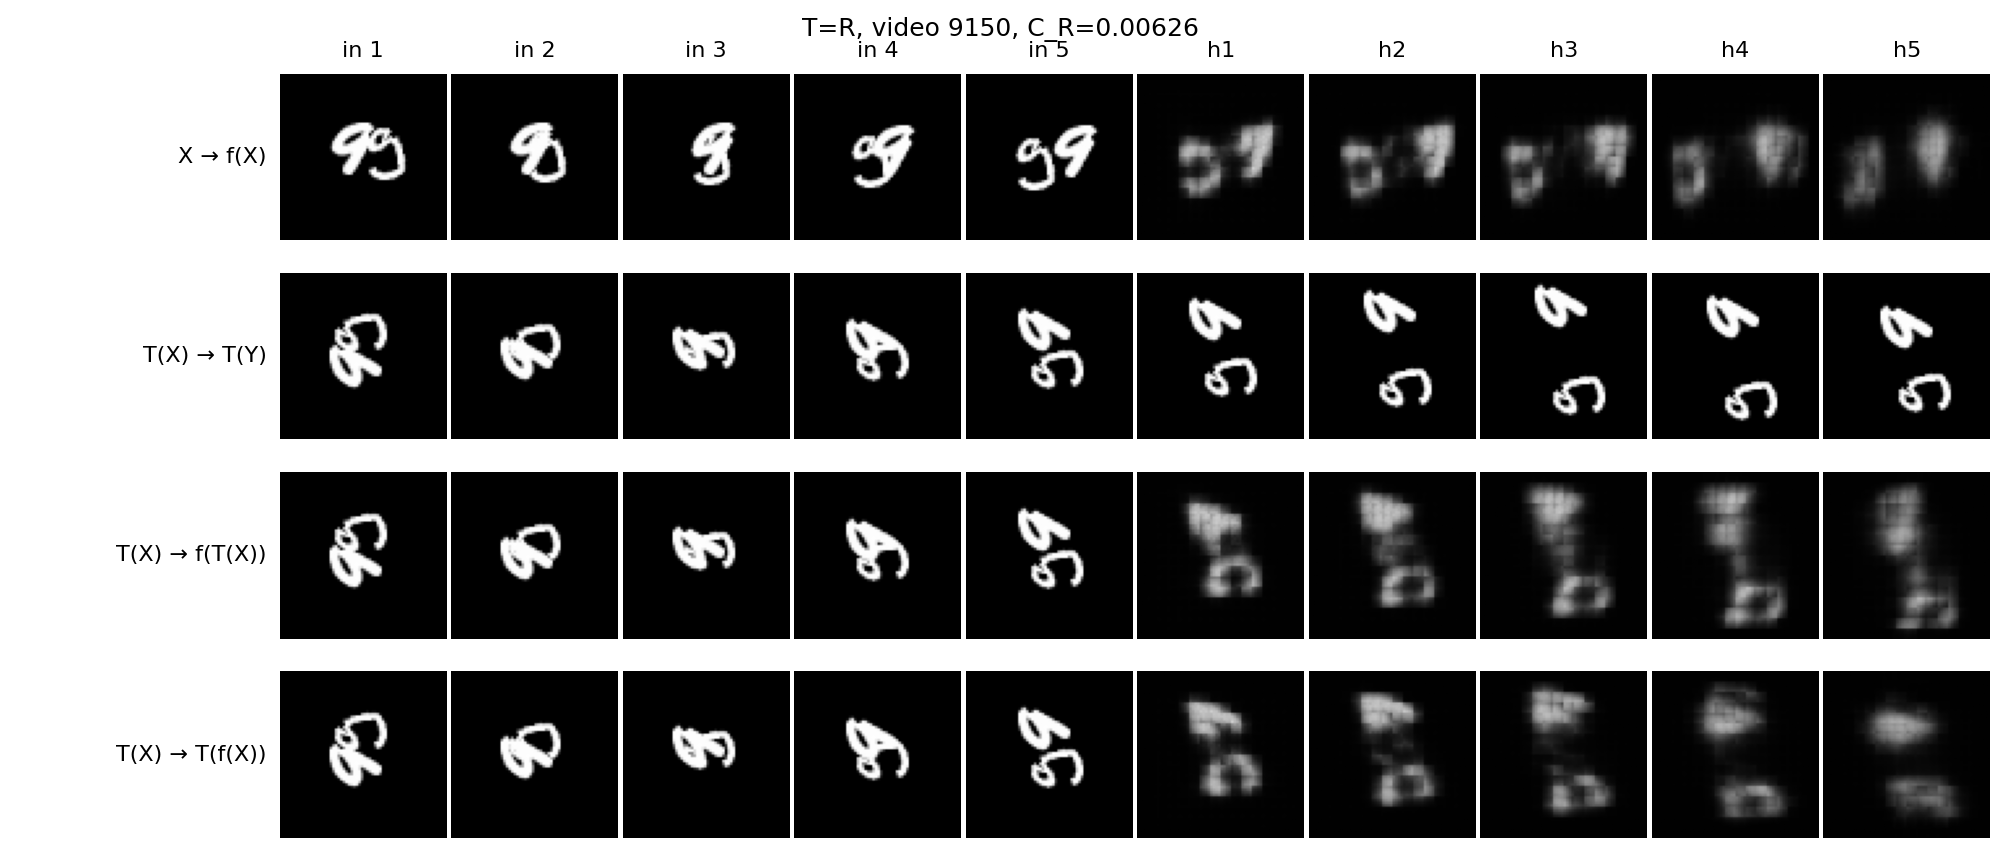

figures/fig4.png


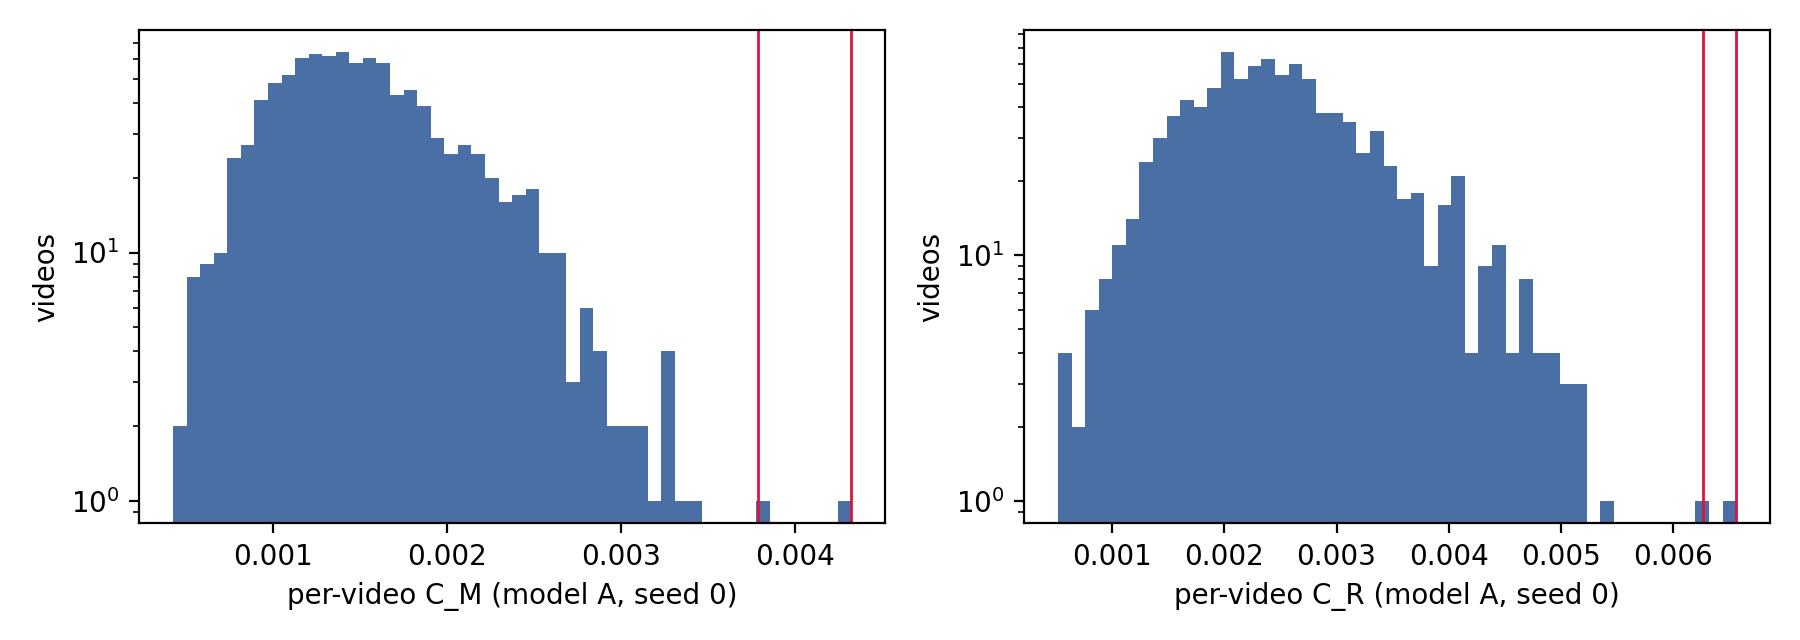

figures/fig5.png


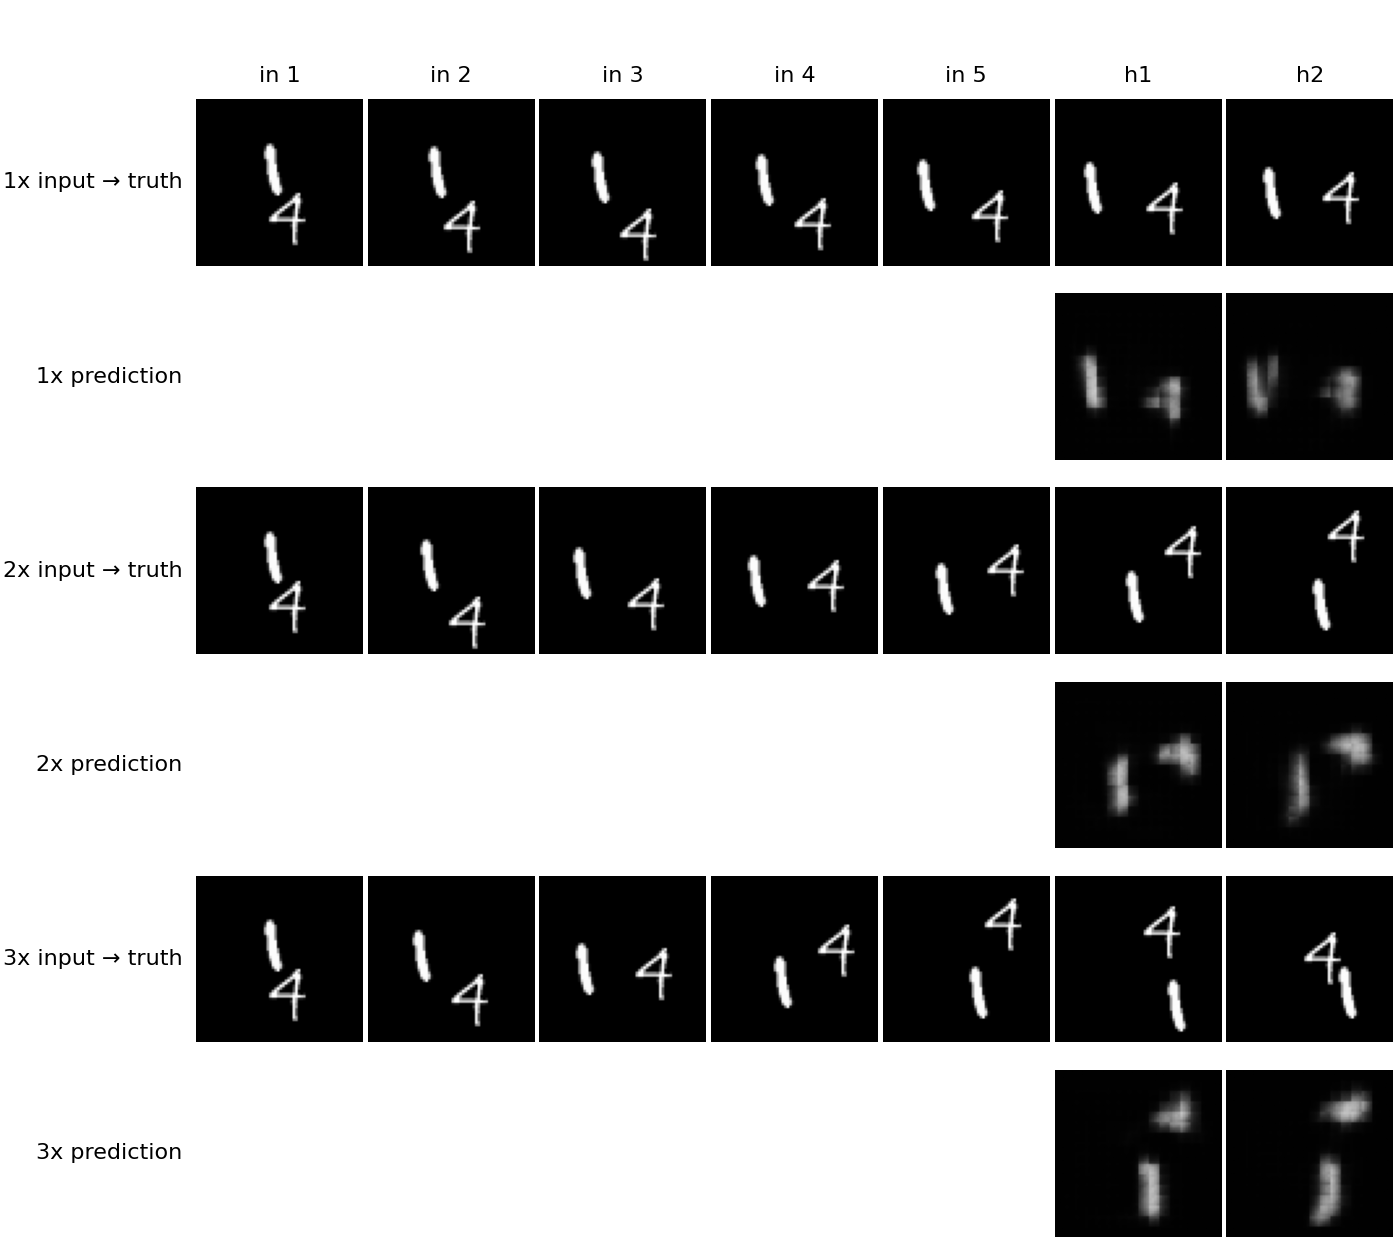

In [5]:
# 5. Stress tests on model A: Tables 3-4, Figures 3-5
!python stage_A2.py
!cat results/table3.md results/table4.md
import glob
for f in sorted(glob.glob('figures/fig3_*.png')) + ['figures/fig4.png', 'figures/fig5.png']:
    print(f); display(Image(f))

In [6]:
# 6. Models B, C and the two Model D candidates (seed 0)
for m, s in [('B', 0), ('B', 1), ('C', 0), ('C', 1), ('D_p8', 0), ('D_dil2', 0)]:
    !python train.py --model $m --seed $s

B seed 0: params=480784, reach=8px, device=cuda, speed_aug=False, sym_aug=True
{'epoch': 1, 'train_loss': 0.04610032716393471, 'sec': 12.296146869659424, 'val_E5': 0.039315830916166306}
{'epoch': 2, 'train_loss': 0.03968675149977207, 'sec': 11.689454555511475, 'val_E5': 0.0385364331305027}
{'epoch': 3, 'train_loss': 0.03864648856222629, 'sec': 11.401094913482666, 'val_E5': 0.03738654404878616}
{'epoch': 4, 'train_loss': 0.037074149295687676, 'sec': 11.290443658828735, 'val_E5': 0.035425879061222076}
{'epoch': 5, 'train_loss': 0.035239756681025025, 'sec': 11.211822509765625, 'val_E5': 0.03420691564679146}
{'epoch': 6, 'train_loss': 0.03358436226099729, 'sec': 11.236202716827393, 'val_E5': 0.03223739191889763}
{'epoch': 7, 'train_loss': 0.03234702438861132, 'sec': 11.335780143737793, 'val_E5': 0.03126978874206543}
{'epoch': 8, 'train_loss': 0.031381985649466516, 'sec': 11.4233078956604, 'val_E5': 0.030389081686735153}
{'epoch': 9, 'train_loss': 0.030560664303600788, 'sec': 11.42806482315

In [7]:
# 7. Choose Model D on validation only, train its seed 1, then Tables 5-6 and Figure 6
!python select_D.py
!python train.py --model D --seed 1
!python stage_final.py
!cat results/table5.md results/table6.md
for f in sorted(glob.glob('figures/fig6a_*.png')) + ['figures/fig6b.png']:
    print(f); display(Image(f))

D_p8 {"params": 594496, "reach_px": 16, "val_E5_1x": 0.03946920856833458, "val_E2": {"1x": 0.039491038769483566, "2x": 0.03946356102824211, "3x": 0.039457157254219055}, "score": 0.039470585683981575}
D_dil2 {"params": 480784, "reach_px": 16, "val_E5_1x": 0.030069245025515556, "val_E2": {"1x": 0.027775077149271965, "2x": 0.03041793778538704, "3x": 0.032278548926115036}, "score": 0.030157187953591347}
chosen (validation only): D_dil2
seed-0 run copied to /content/runs/D_seed0. Now: python train.py --model D --seed 1
D seed 1: params=480784, reach=16px, device=cuda, speed_aug=True, sym_aug=False
{'epoch': 1, 'train_loss': 0.04833925741910934, 'sec': 20.79126763343811, 'val_E5': 0.03947661444544792}
{'epoch': 2, 'train_loss': 0.04020841267704964, 'sec': 20.10157036781311, 'val_E5': 0.039471328258514404}
{'epoch': 3, 'train_loss': 0.04017768558859825, 'sec': 19.612878799438477, 'val_E5': 0.03947129845619202}
{'epoch': 4, 'train_loss': 0.040108397006988525, 'sec': 19.5469753742218, 'val_E5':

FileNotFoundError: No such file or directory: 'figures/fig6b.png'

FileNotFoundError: No such file or directory: 'figures/fig6b.png'

<IPython.core.display.Image object>

In [8]:
# 8. Timing record and download of all outputs (tables, figures, GIFs)
import json
for f in sorted(glob.glob('/content/runs/*/log.json')):
    d = json.load(open(f))
    print(f"{d['model']:7s} seed {d['seed']}  params {d['params']:>8,}  reach {d['reach_px']:>2} px  {d['mean_epoch_sec']:.1f} s/epoch  [{d['hardware']}]")
%cd /content/DLSTG
!zip -qr /content/pa2_outputs.zip Question1/figures Question2/results Question2/figures
from google.colab import files
files.download('/content/pa2_outputs.zip')

A       seed 0  params  480,784  reach  8 px  10.8 s/epoch  [CUDA GPU: Tesla T4]
A       seed 1  params  480,784  reach  8 px  10.9 s/epoch  [CUDA GPU: Tesla T4]
B       seed 0  params  480,784  reach  8 px  11.4 s/epoch  [CUDA GPU: Tesla T4]
B       seed 1  params  480,784  reach  8 px  11.4 s/epoch  [CUDA GPU: Tesla T4]
C       seed 0  params  480,784  reach  8 px  10.7 s/epoch  [CUDA GPU: Tesla T4]
C       seed 1  params  480,784  reach  8 px  10.7 s/epoch  [CUDA GPU: Tesla T4]
D_dil2  seed 0  params  480,784  reach 16 px  19.8 s/epoch  [CUDA GPU: Tesla T4]
D_p8    seed 0  params  594,496  reach 16 px  4.2 s/epoch  [CUDA GPU: Tesla T4]
D_dil2  seed 0  params  480,784  reach 16 px  19.8 s/epoch  [CUDA GPU: Tesla T4]
D       seed 1  params  480,784  reach 16 px  20.0 s/epoch  [CUDA GPU: Tesla T4]
/content/DLSTG


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>